## MLPI Textbook — Chapter 5 companion notebook

# Ensemble Learning: Diagnosing a Robot Wrist Gearbox

### Majority voting, bagging, AdaBoost, gradient boosting, random forests and stacking

---

The wrist joints of a 6-axis robot carry compact, heavily loaded gearboxes. When one fails in
production the line stops, and the usual root causes — **bearing outer-race wear** and
**gear tooth wear** — develop slowly over weeks. A cheap accelerometer on the housing, plus the
drive current the controller already measures, can catch them early.

Every night the robot runs a short, identical test move and logs a 2-second recording. Signal
processing turns each recording into **13 condition indicators** (overall vibration level,
impulsiveness, energy in frequency bands tied to the shaft, the gear mesh and the bearing
defect frequency, current, temperature). The task: classify each recording as
**healthy, bearing wear, or gear tooth wear**.

No single model is perfect at this, and that is the opening for **ensembles**: combine many
imperfect models into one that is better than any of them.

### What you will be able to do afterwards

1. Explain *why* combining classifiers reduces error, and when it does not.
2. Build a **majority-vote** ensemble from different model families.
3. Reduce variance with **bagging** and see what it does to a decision tree's boundary.
4. Follow **AdaBoost**'s sample re-weighting by hand, then use it in scikit-learn.
5. Use **gradient boosting** (scikit-learn and XGBoost) and **random forests**, and read
   **feature importances** in physical terms.
6. **Stack** models with a meta-learner.

| § | topic |
|---|---|
| 1 | the data — condition indicators from a wrist gearbox |
| 2 | why ensembles work |
| 3 | majority voting |
| 4 | bagging |
| 5 | adaptive boosting |
| 6 | gradient boosting and XGBoost |
| 7 | random forests and feature importance |
| 8 | stacking, and the final comparison |

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE, AQUA]

RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1


In [2]:
from matplotlib.colors import ListedColormap


def plot_decision_regions(X, y, classifier, ax=None, names=None, resolution=300,
                          test_idx=None, xlabel=None, ylabel=None):
    """Shade the region each class wins in a 2-feature plane and overlay the samples."""
    ax = ax or plt.gca()
    classes = np.unique(y)
    cmap = ListedColormap(CLASS_COLORS[:len(classes)])
    pad_x = 0.08 * np.ptp(X[:, 0]); pad_y = 0.08 * np.ptp(X[:, 1])
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad_x, X[:, 0].max() + pad_x, resolution),
                         np.linspace(X[:, 1].min() - pad_y, X[:, 1].max() + pad_y, resolution))
    Z = classifier.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(len(classes) + 1) - 0.5, alpha=0.18, cmap=cmap)
    markers = ["o", "s", "^"]
    for i, c in enumerate(classes):
        lab = names[c] if names is not None else f"class {c}"
        ax.scatter(X[y == c, 0], X[y == c, 1], s=16, color=CLASS_COLORS[i],
                   marker=markers[i], edgecolor="white", linewidth=0.4, label=lab)
    if test_idx is not None:
        ax.scatter(X[test_idx, 0], X[test_idx, 1], s=70, facecolor="none",
                   edgecolor="#333", linewidth=0.8, label="test set")
    ax.set_xlim(xx.min(), xx.max()); ax.set_ylim(yy.min(), yy.max())
    if xlabel: ax.set_xlabel(xlabel)
    if ylabel: ax.set_ylabel(ylabel)
    return ax

---
## 1. The data

Synthetic but physically built (no download needed). Each fault has a **severity** between 0
(just starting) and 1 (severe), drawn so that many faulty units are still *incipient* and look
nearly healthy — exactly the cases that make diagnosis hard. Load and speed of the test move
vary a little from night to night and change every vibration energy, which makes the features
correlated with each other (that matters again in Chapter 6).

| feature | physical meaning | grows with |
|---|---|---|
| `rms_g` | overall vibration level | everything |
| `peak_g`, `crest_factor` | largest spike, spike / RMS | impacts |
| `kurtosis` | impulsiveness (3 for Gaussian noise) | **bearing** defects |
| `skewness` | asymmetry of the signal | — (weak) |
| `e_1x`, `e_2x` | energy at 1× and 2× shaft speed | imbalance / **gear** wear |
| `e_gmf` | energy at the gear-mesh frequency | load, **gear** wear |
| `e_sideband` | sidebands around the mesh frequency | **gear** tooth damage |
| `e_bearing` | energy at the bearing defect frequency | **bearing** wear |
| `e_hf_envelope` | high-frequency envelope energy | **bearing** impacts |
| `motor_current_A` | drive current RMS | load |
| `housing_temp_C` | gearbox housing temperature | load × speed, friction |

In [3]:
FAULT_NAMES = ["healthy", "bearing wear", "gear tooth wear"]
GEAR_FEATURES = ["rms_g", "peak_g", "crest_factor", "kurtosis", "skewness",
                 "e_1x", "e_2x", "e_gmf", "e_sideband", "e_bearing", "e_hf_envelope",
                 "motor_current_A", "housing_temp_C"]


def make_gearbox_dataset(n_per_class=160, seed=11):
    """Condition-monitoring snapshots from the wrist gearbox of a 6-axis robot.

    Each row summarises one 2-second accelerometer + drive-current recording
    taken while the joint runs a test move. Label `condition`:
    0 = healthy, 1 = bearing outer-race wear, 2 = gear tooth wear.
    """
    rng = np.random.default_rng(seed)
    frames = []
    for label in (0, 1, 2):
        n = n_per_class
        load = rng.uniform(0.2, 1.0, n)                 # fraction of rated torque
        speed = rng.uniform(0.3, 1.0, n)                # fraction of rated speed
        sev = np.zeros(n) if label == 0 else rng.beta(2.0, 1.6, n)   # 0 = incipient, 1 = severe
        bear = sev if label == 1 else np.zeros(n)
        gear = sev if label == 2 else np.zeros(n)
        ln = lambda s: rng.lognormal(0.0, s, n)          # multiplicative sensor/process noise

        e_1x = (0.30 + 0.25 * speed) * ln(0.25)
        e_2x = (0.12 + 0.08 * speed + 0.20 * gear) * ln(0.30)
        e_gmf = (0.50 + 0.60 * load * speed + 0.55 * gear) * ln(0.22)
        e_side = (0.06 + 0.04 * load + 0.42 * gear**1.3) * ln(0.35)
        e_bear = (0.05 + 0.03 * speed + 0.50 * bear**1.2) * ln(0.35)
        e_hf = (0.10 + 0.05 * speed + 0.35 * bear + 0.08 * gear) * ln(0.30)
        rms = np.sqrt(e_1x + e_2x + e_gmf + e_side + e_bear + e_hf)
        kurt = 3.0 + 4.5 * bear**1.5 + 1.2 * gear + rng.gamma(2.0, 0.25, n)
        crest = 2.9 + 0.55 * (kurt - 3.0) + rng.normal(0, 0.25, n)
        peak = crest * rms
        skew = rng.normal(0, 0.12, n) + 0.30 * bear - 0.10 * gear
        current = (2.0 + 4.5 * load + 0.25 * speed + 0.35 * gear) * ln(0.05)
        temp = 34 + 14 * load * speed + 3.0 * bear + 4.0 * gear + rng.normal(0, 2.2, n)
        frames.append(pd.DataFrame(dict(
            rms_g=rms, peak_g=peak, crest_factor=crest, kurtosis=kurt, skewness=skew,
            e_1x=e_1x, e_2x=e_2x, e_gmf=e_gmf, e_sideband=e_side, e_bearing=e_bear,
            e_hf_envelope=e_hf, motor_current_A=current, housing_temp_C=temp,
            condition=label)))
    df = pd.concat(frames, ignore_index=True)
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)


gb = make_gearbox_dataset()
X_all = gb[GEAR_FEATURES].to_numpy()
y_all = gb["condition"].to_numpy()
print(gb.shape, " class counts:", np.bincount(y_all))
gb.groupby("condition")[GEAR_FEATURES].mean().rename(index=dict(enumerate(FAULT_NAMES))).T.round(3)

(480, 14)  class counts: [160 160 160]


condition,healthy,bearing wear,gear tooth wear
rms_g,1.296,1.459,1.540
peak_g,4.111,6.257,5.465
crest_factor,3.172,4.254,3.543
kurtosis,3.512,5.448,4.147
skewness,0.004,0.164,-0.063
e_1x,0.485,0.473,0.471
e_2x,0.178,0.173,0.296
e_gmf,0.727,0.743,1.064
e_sideband,0.089,0.089,0.307
e_bearing,0.074,0.344,0.075


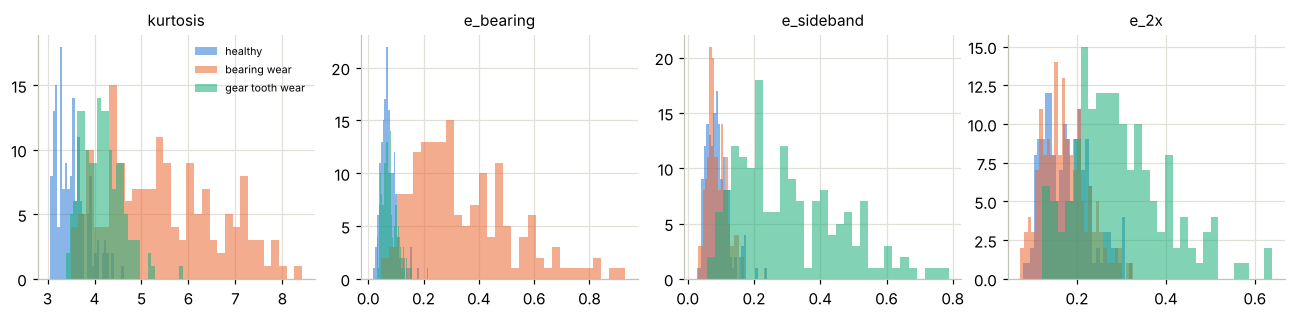

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, f in zip(axes, ["kurtosis", "e_bearing", "e_sideband", "e_2x"]):
    for c in range(3):
        ax.hist(gb.loc[gb.condition == c, f], bins=30, alpha=0.55, color=CLASS_COLORS[c], label=FAULT_NAMES[c])
    ax.set_title(f, fontsize=10)
axes[0].legend(fontsize=7)
plt.tight_layout(); savefig("ch05_feature_hists"); plt.show()

Each fault lights up *its own* indicators — bearing wear raises kurtosis and the bearing band,
gear wear raises the sidebands — but every histogram has a long overlap with "healthy": those
are the incipient faults.

---
## 2. Why ensembles work

Suppose we have $n$ classifiers, each with error rate $\varepsilon$, whose mistakes are
**independent**. A majority vote is wrong only if more than half of them are wrong at once:
$$\varepsilon_\text{ens} = \sum_{k=\lceil n/2\rceil}^{n}\binom{n}{k}\varepsilon^k(1-\varepsilon)^{n-k}.$$

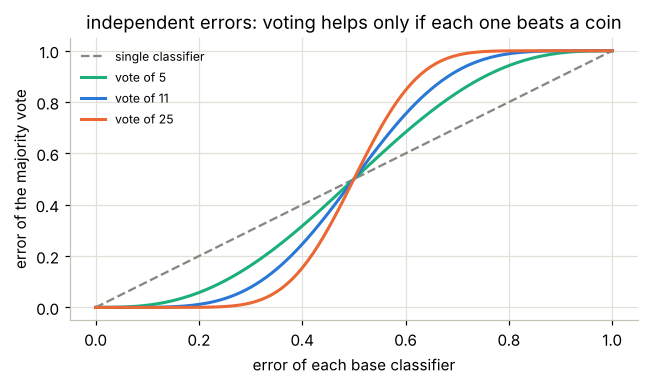

11 classifiers at 25 % error each -> ensemble error 0.034


In [5]:
from scipy.special import comb


def ensemble_error(n, eps):
    k0 = int(np.ceil(n / 2.0))
    return sum(comb(n, k) * eps ** k * (1 - eps) ** (n - k) for k in range(k0, n + 1))


eps = np.linspace(0, 1, 101)
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(eps, eps, color=MUTED, ls="--", lw=1.5, label="single classifier")
for n, col in [(5, AQUA), (11, BLUE), (25, ORANGE)]:
    ax.plot(eps, [ensemble_error(n, e) for e in eps], color=col, lw=2, label=f"vote of {n}")
ax.set_xlabel("error of each base classifier"); ax.set_ylabel("error of the majority vote")
ax.legend(fontsize=8); ax.set_title("independent errors: voting helps only if each one beats a coin")
plt.tight_layout(); savefig("ch05_ensemble_error"); plt.show()
print(f"11 classifiers at 25 % error each -> ensemble error {ensemble_error(11, 0.25):.3f}")

Two conditions hide in that formula, and both matter in practice:

1. Each base model must be **better than chance** ($\varepsilon < 0.5$). Below the diagonal on
   the left, voting helps; above it on the right, it makes things worse.
2. The errors must be **independent**. Ten copies of the same model make the same mistakes and
   gain nothing. Every ensemble method in this chapter is a different trick for producing
   *diverse* models: different algorithms (§3), different bootstrap samples (§4, §7),
   re-weighted samples (§5), or models fitted to each other's residuals (§6).

---
## 3. Majority voting

We first make a **binary** task: *healthy* (0) vs *any fault* (1) — the question the
maintenance planner actually asks first — and hold out a test set.

In [6]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

y_bin = (y_all > 0).astype(int)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_all, y_bin, test_size=0.3, stratify=y_bin,
                                              random_state=RANDOM_STATE)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print("train:", np.bincount(yb_tr), " test:", np.bincount(yb_te))

train: [112 224]  test: [48 96]


Three deliberately different, deliberately simple base models — a linear model on two
features, a depth-1 tree ("stump"), and k-NN on four features. A small `ColumnSelector` makes
each one see a different slice of the data, which is one cheap way to get **diverse** errors.

The ensemble itself is a dozen lines: average the predicted class probabilities (**soft
voting**) and take the most probable class.

In [7]:
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, roc_curve


class ColumnSelector(TransformerMixin, BaseEstimator):     # mixins go first (sklearn >= 1.6)
    def __init__(self, cols=None):
        self.cols = cols
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[:, self.cols]


class MajorityVoteClassifier(ClassifierMixin, BaseEstimator):
    """Soft majority vote: average the class probabilities of the member models."""

    def __init__(self, classifiers, weights=None):
        self.classifiers, self.weights = classifiers, weights

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.fitted_ = [clone(c).fit(X, y) for c in self.classifiers]
        return self

    def predict_proba(self, X):
        probas = np.array([c.predict_proba(X) for c in self.fitted_])
        return np.average(probas, axis=0, weights=self.weights)

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


col = {f: i for i, f in enumerate(GEAR_FEATURES)}
clf_lr = make_pipeline(ColumnSelector([col["rms_g"], col["e_gmf"]]), StandardScaler(),
                       LogisticRegression())
clf_stump = make_pipeline(ColumnSelector([col["kurtosis"]]), DecisionTreeClassifier(max_depth=1))
clf_knn = make_pipeline(ColumnSelector([col["e_sideband"], col["e_bearing"], col["e_2x"], col["e_hf_envelope"]]),
                        StandardScaler(), KNeighborsClassifier(n_neighbors=15))
vote = MajorityVoteClassifier([clf_lr, clf_stump, clf_knn])

members = {"logistic regression (rms, gmf)": clf_lr, "stump (kurtosis)": clf_stump,
           "k-NN (4 band energies)": clf_knn, "majority vote": vote}
for name, m in members.items():
    s = cross_val_score(m, Xb_tr, yb_tr, cv=cv, scoring="roc_auc")
    print(f"{name:32s} ROC AUC {s.mean():.3f} ± {s.std():.3f}")

logistic regression (rms, gmf)   ROC AUC 0.906 ± 0.023
stump (kurtosis)                 ROC AUC 0.819 ± 0.046
k-NN (4 band energies)           ROC AUC 0.967 ± 0.010


majority vote                    ROC AUC 0.975 ± 0.015


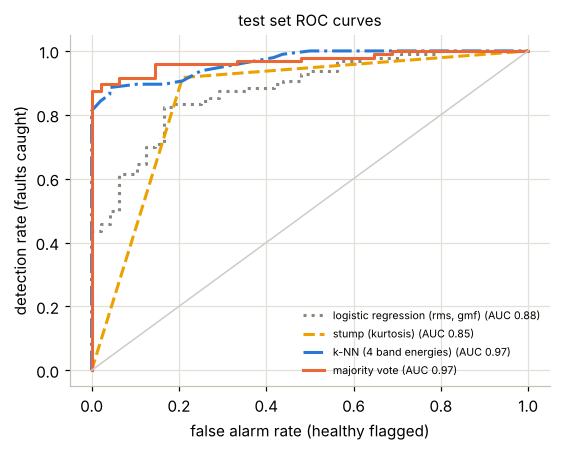

In [8]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for (name, m), c, ls in zip(members.items(), [MUTED, YELLOW, BLUE, ORANGE], [":", "--", "-.", "-"]):
    p = m.fit(Xb_tr, yb_tr).predict_proba(Xb_te)[:, 1]
    fpr, tpr, _ = roc_curve(yb_te, p)
    ax.plot(fpr, tpr, color=c, ls=ls, lw=2, label=f"{name} (AUC {roc_auc_score(yb_te, p):.2f})")
ax.plot([0, 1], [0, 1], color="#ccc", lw=1)
ax.set_xlabel("false alarm rate (healthy flagged)"); ax.set_ylabel("detection rate (faults caught)")
ax.legend(fontsize=7, loc="lower right"); ax.set_title("test set ROC curves", fontsize=10)
plt.tight_layout(); savefig("ch05_vote_roc"); plt.show()

In cross-validation the vote beats every one of its members, including the strong k-NN:
each model sees a different symptom, so their mistakes are only partly correlated. On the small
test set it ties k-NN on AUC but dominates the low-false-alarm corner of the ROC plot, which is
where a maintenance planner operates. (ROC curves and AUC are covered properly in Chapter 7; here read them as
"further up and to the left is better".)

scikit-learn ships the same idea as `sklearn.ensemble.VotingClassifier(voting="soft")`.

---
## 4. Bagging — bootstrap aggregating

Bagging trains the **same** algorithm many times, each on a **bootstrap sample** (draw $n$
samples *with replacement* from the $n$ training samples, so roughly 63 % of them appear, some
repeatedly), and votes. It attacks **variance**: unpruned decision trees overfit in different
ways on different samples, and averaging cancels much of that out.

To *see* it, take the hardest pair — **healthy vs gear tooth wear** — and two features,
sideband energy and 2× shaft energy.

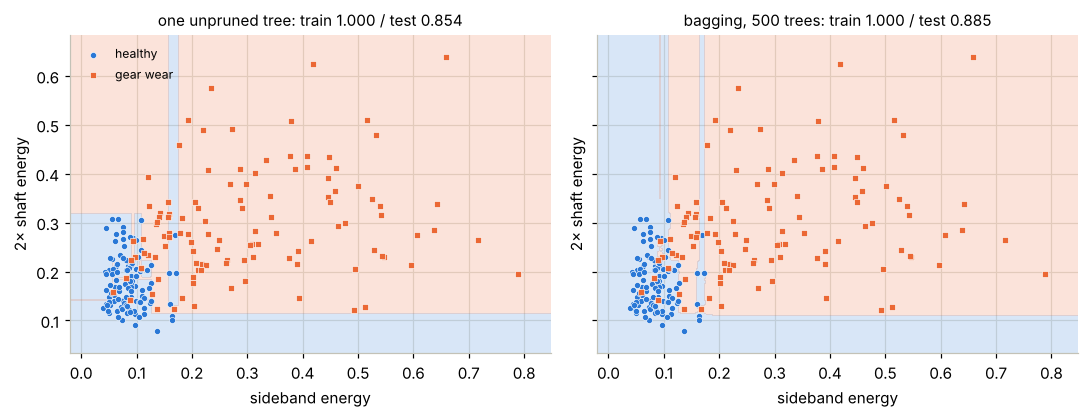

In [9]:
from sklearn.ensemble import BaggingClassifier

pair = np.isin(y_all, [0, 2])
F2 = [col["e_sideband"], col["e_2x"]]
X_hg = X_all[pair][:, F2]
y_hg = (y_all[pair] == 2).astype(int)
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(X_hg, y_hg, test_size=0.3, stratify=y_hg, random_state=1)
HG_NAMES = ["healthy", "gear wear"]
LAB_HG = dict(xlabel="sideband energy", ylabel="2× shaft energy")

tree = DecisionTreeClassifier(random_state=1)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=500, random_state=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, (name, m) in zip(axes, [("one unpruned tree", tree), ("bagging, 500 trees", bag)]):
    m.fit(Xh_tr, yh_tr)
    plot_decision_regions(Xh_tr, yh_tr, m, ax=ax, names=HG_NAMES, **LAB_HG)
    ax.set_title(f"{name}: train {m.score(Xh_tr, yh_tr):.3f} / test {m.score(Xh_te, yh_te):.3f}", fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("ch05_bagging"); plt.show()

Both fit the training set perfectly, but the single tree's boundary is a patchwork of thin
slivers around individual points. The bagged boundary is smoother and generalises better.
Bagging does **not** fix bias: bagging a stump still gives a stump-like boundary.

---
## 5. Adaptive boosting (AdaBoost)

Boosting works the other way round: start from **weak learners** with high bias (stumps) and
train them **sequentially**, each one concentrating on the samples the previous ones got
wrong. For labels $y\in\{-1,+1\}$:

1. Start with equal sample weights $w_i = 1/n$.
2. For $j = 1 \dots m$:
   * fit weak learner $C_j$ on the weighted data, predictions $\hat y_i$;
   * weighted error $\varepsilon_j = \sum_i w_i\,[\hat y_i \ne y_i]$;
   * learner weight $\alpha_j = \tfrac12\ln\dfrac{1-\varepsilon_j}{\varepsilon_j}$;
   * update $w_i \leftarrow w_i\,\exp(-\alpha_j\,\hat y_i\,y_i)$ and normalise so $\sum w_i = 1$.
3. Predict $\operatorname{sign}\big(\sum_j \alpha_j C_j(\mathbf x)\big)$.

### 5.1 One round by hand

Ten nightly recordings, one feature (sideband energy), and a stump that says "gear wear if
sideband > 0.15":

In [10]:
side = np.array([0.05, 0.08, 0.11, 0.13, 0.14, 0.16, 0.19, 0.22, 0.26, 0.31])
y_true = np.array([-1, -1, -1, 1, -1, -1, 1, 1, 1, 1])     # +1 = gear wear
y_hat = np.where(side > 0.15, 1, -1)
w = np.full(10, 0.1)

wrong = y_hat != y_true
eps_ = w[wrong].sum()
alpha = 0.5 * np.log((1 - eps_) / eps_)
w_new = w * np.exp(-alpha * y_hat * y_true); w_new /= w_new.sum()

pd.DataFrame(dict(sideband=side, true=y_true, stump=y_hat, correct=~wrong,
                  w_before=w, w_after=w_new.round(3)))

,sideband,true,stump,correct,w_before,w_after
0,0.05,-1,-1,True,0.1,0.062
1,0.08,-1,-1,True,0.1,0.062
2,0.11,-1,-1,True,0.1,0.062
3,0.13,1,-1,False,0.1,0.250
4,0.14,-1,-1,True,0.1,0.062
5,0.16,-1,1,False,0.1,0.250
6,0.19,1,1,True,0.1,0.062
7,0.22,1,1,True,0.1,0.062
8,0.26,1,1,True,0.1,0.062
9,0.31,1,1,True,0.1,0.062


In [11]:
print(f"weighted error eps = {eps_:.2f},  alpha = {alpha:.3f}")
print(f"each misclassified sample now weighs {w_new[wrong][0]:.3f}, each correct one {w_new[~wrong][0]:.3f}")

weighted error eps = 0.20,  alpha = 0.693
each misclassified sample now weighs 0.250, each correct one 0.062


The two misclassified recordings (an incipient gear fault at 0.13 and a healthy unit at 0.16)
now carry as much total weight as the eight correct ones together, so the *next* stump is
forced to deal with them.

### 5.2 AdaBoost in scikit-learn

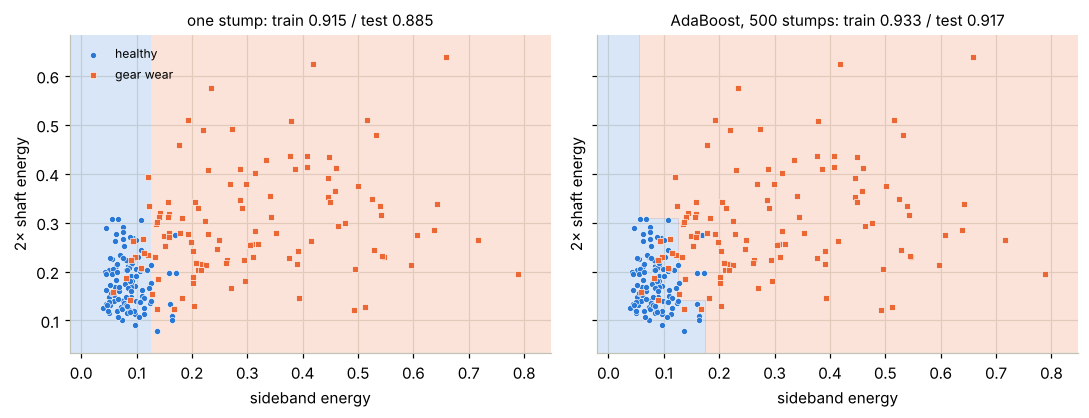

In [12]:
from sklearn.ensemble import AdaBoostClassifier

stump = DecisionTreeClassifier(max_depth=1)
ada = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=500,
                         learning_rate=0.1, random_state=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
for ax, (name, m) in zip(axes, [("one stump", stump), ("AdaBoost, 500 stumps", ada)]):
    m.fit(Xh_tr, yh_tr)
    plot_decision_regions(Xh_tr, yh_tr, m, ax=ax, names=HG_NAMES, **LAB_HG)
    ax.set_title(f"{name}: train {m.score(Xh_tr, yh_tr):.3f} / test {m.score(Xh_te, yh_te):.3f}", fontsize=10)
axes[0].legend(fontsize=8)
plt.tight_layout(); savefig("ch05_adaboost"); plt.show()

A stump can draw exactly one line. AdaBoost's weighted sum of 500 stumps draws a staircase that
uses *both* features — lower bias, and here better test accuracy than both the single stump and
the bagged trees.

---
## 6. Gradient boosting and XGBoost

Gradient boosting also builds trees sequentially, but instead of re-weighting samples, each new
tree is fitted to the **negative gradient of the loss** with respect to the current
prediction — for squared error, simply the **residuals**. The model after $m$ trees is
$$F_m(\mathbf x) = F_{m-1}(\mathbf x) + \eta\,h_m(\mathbf x),$$
where $h_m$ is a small tree (depth 2–6) and $\eta$ the learning rate ("shrinkage"). For
classification the trees fit gradients of the log-loss on the log-odds scale.

Now we return to the full **three-class** problem with all 13 features.

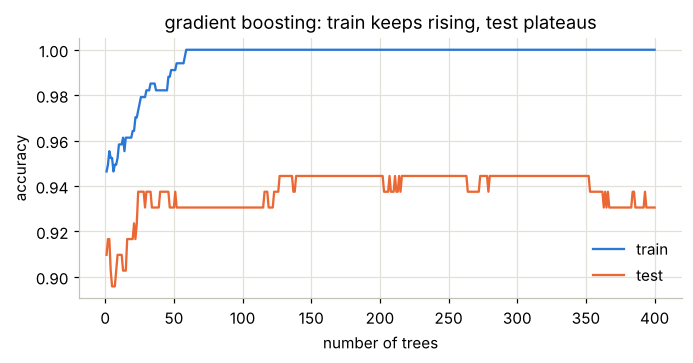

best test accuracy 0.944 at 127 trees; final 0.931


In [13]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.3, stratify=y_all,
                                          random_state=RANDOM_STATE)

gbm = GradientBoostingClassifier(n_estimators=400, learning_rate=0.05, max_depth=3,
                                 subsample=0.8, random_state=1).fit(X_tr, y_tr)
tr_curve = [accuracy_score(y_tr, p) for p in gbm.staged_predict(X_tr)]
te_curve = [accuracy_score(y_te, p) for p in gbm.staged_predict(X_te)]

fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(range(1, 401), tr_curve, color=BLUE, label="train"); ax.plot(range(1, 401), te_curve, color=ORANGE, label="test")
ax.set_xlabel("number of trees"); ax.set_ylabel("accuracy"); ax.legend()
ax.set_title("gradient boosting: train keeps rising, test plateaus")
plt.tight_layout(); savefig("ch05_gbm_staged"); plt.show()
print(f"best test accuracy {max(te_curve):.3f} at {int(np.argmax(te_curve)) + 1} trees; "
      f"final {te_curve[-1]:.3f}")

**XGBoost** is an optimised implementation of the same idea with built-in regularisation,
fast histogram-based splits and good defaults, and it is a standard tool for tabular data in
industry. scikit-learn's own `HistGradientBoostingClassifier` is a close equivalent with no
extra dependency; the cell below uses XGBoost if it is installed and falls back otherwise.

In [14]:
try:
    from xgboost import XGBClassifier
    fast_gb = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                            colsample_bytree=0.8, random_state=1, verbosity=0)
    fast_name = "XGBoost"
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    fast_gb = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=1)
    fast_name = "HistGradientBoosting (xgboost not installed)"

fast_gb.fit(X_tr, y_tr)
print(f"{fast_name}: test accuracy {accuracy_score(y_te, fast_gb.predict(X_te)):.3f}")

XGBoost: test accuracy 0.931


---
## 7. Random forests and feature importance

A **random forest** is bagging of decision trees plus one extra source of diversity: at each
split, a tree may only choose among a **random subset of the features** (by default
$\sqrt{m}$ of them). That stops every tree from splitting on the same dominant feature and
de-correlates their errors.

A forest also tells you which features it relied on. **Impurity-based importance** sums the
impurity decrease each feature produced across all splits. It is fast but biased toward
features with many distinct values; **permutation importance** — shuffle one feature on the
*test* set and measure how much accuracy drops — is slower but more trustworthy.

random forest test accuracy 0.931


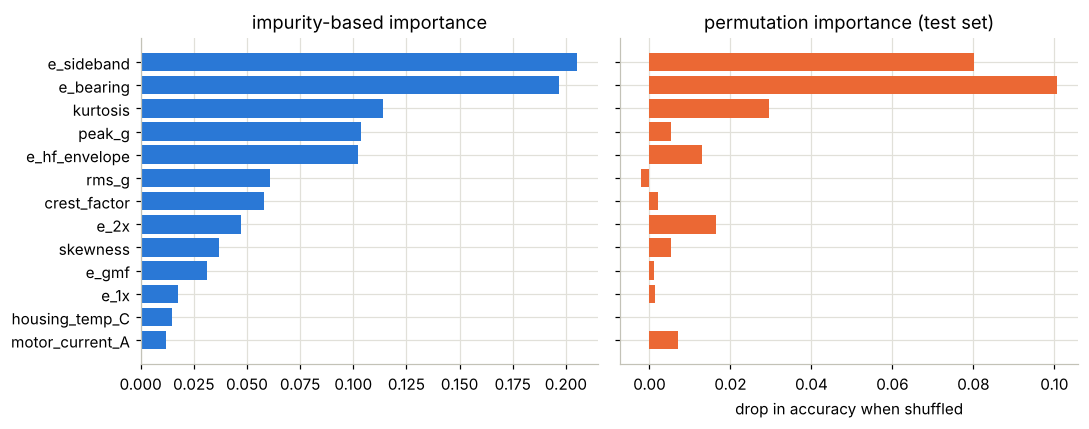

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

forest = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1).fit(X_tr, y_tr)
print(f"random forest test accuracy {forest.score(X_te, y_te):.3f}")

imp = pd.DataFrame({"impurity": forest.feature_importances_,
                    "permutation": permutation_importance(forest, X_te, y_te, n_repeats=20,
                                                          random_state=1).importances_mean},
                   index=GEAR_FEATURES).sort_values("impurity")
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].barh(imp.index, imp.impurity, color=BLUE); ax[0].set_title("impurity-based importance")
ax[1].barh(imp.index, imp.permutation, color=ORANGE); ax[1].set_title("permutation importance (test set)")
ax[1].set_xlabel("drop in accuracy when shuffled")
plt.tight_layout(); savefig("ch05_rf_importance"); plt.show()

The forest has rediscovered the physics: the **bearing-band energy** and **sideband energy**
— the two indicators a vibration analyst would check first — come out on top, followed by the
impulsiveness measures (kurtosis, peak, crest factor, envelope). Load-driven quantities such as
current and temperature rank low: they vary with the test move, not with the fault.

Permutation importance spreads credit differently between correlated features (kurtosis, crest
factor and peak carry nearly the same information, so shuffling any one of them costs little).
Keep that in mind before deleting a "useless" sensor.

---
## 8. Stacking, and the final comparison

**Stacking** trains a *meta-learner* on the predictions of the base models. To avoid the
meta-learner seeing predictions on data the base models were trained on, scikit-learn's
`StackingClassifier` feeds it **out-of-fold** predictions produced by internal
cross-validation.

In [16]:
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV   # gives the SVM predict_proba

base = [("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
        ("svm", make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(C=3.0), ensemble=False))),
        ("rf", RandomForestClassifier(n_estimators=300, random_state=1, n_jobs=-1))]

models = {
    "decision tree": DecisionTreeClassifier(random_state=1),
    "logistic regression": base[0][1],
    "RBF SVM": base[1][1],
    "bagging (500 trees)": BaggingClassifier(DecisionTreeClassifier(), n_estimators=500, random_state=1, n_jobs=-1),
    "AdaBoost (stumps)": AdaBoostClassifier(n_estimators=300, learning_rate=0.5, random_state=1),
    "gradient boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, subsample=0.8, random_state=1),
    fast_name.split(" ")[0]: fast_gb,
    "random forest": forest,
    "soft vote (lr, svm, rf)": VotingClassifier(base, voting="soft"),
    "stacking (lr, svm, rf -> lr)": StackingClassifier(base, final_estimator=LogisticRegression(max_iter=2000), cv=5),
}
rows = []
for name, m in models.items():
    s = cross_val_score(m, X_tr, y_tr, cv=cv)
    m.fit(X_tr, y_tr)
    rows.append(dict(model=name, cv_acc=s.mean(), cv_std=s.std(), test_acc=m.score(X_te, y_te)))
table = pd.DataFrame(rows).set_index("model").round(3)
table

,cv_acc,cv_std,test_acc
model,,,
decision tree,0.887,0.031,0.847
logistic regression,0.928,0.020,0.958
RBF SVM,0.923,0.017,0.944
bagging (500 trees),0.902,0.022,0.917
AdaBoost (stumps),0.902,0.026,0.924
gradient boosting,0.914,0.024,0.944
XGBoost,0.923,0.026,0.931
random forest,0.917,0.018,0.931
"soft vote (lr, svm, rf)",0.926,0.016,0.951


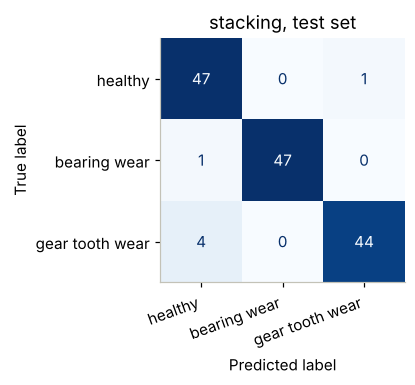

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(models["stacking (lr, svm, rf -> lr)"], X_te, y_te,
                                      display_labels=FAULT_NAMES, cmap="Blues", colorbar=False)
plt.xticks(rotation=20, ha="right"); plt.title("stacking, test set"); plt.grid(False)
plt.tight_layout(); savefig("ch05_confusion"); plt.show()

Read the table with the cross-validation spread in mind: differences of a percent or two
between the ensembles are within noise on a data set of this size. The robust conclusions are:

* every ensemble beats a single unpruned tree, in cross-validation and on the test set;
* on these well-engineered features a **regularised linear model is already competitive**,
  and ensembles add a little on top;
* the remaining errors are almost all **incipient faults labelled healthy** — no algorithm can
  find a fault that has not yet changed the signal. Better sensors or a trend over several
  nights (Chapter 11) is the way forward, not a bigger ensemble.

---
## Summary

| method | trains | reduces | base learner |
|---|---|---|---|
| majority vote | different models in parallel | variance (if errors differ) | anything |
| bagging | same model on bootstrap samples, in parallel | variance | deep trees |
| random forest | bagging + random feature subsets | variance | deep trees |
| AdaBoost | sequentially, re-weighting samples | bias | stumps |
| gradient boosting / XGBoost | sequentially, fitting gradients | bias (and variance via shrinkage) | shallow trees |
| stacking | meta-model on out-of-fold predictions | both | anything |

## Exercises

1. Make the three voting members *less* diverse — give all of them the same two features. How
   much of the vote's advantage remains? Relate your answer to the independence assumption.
2. Plot bagging test accuracy against `n_estimators` (1, 5, 25, 100, 500). Where does it stop
   improving?
3. Rerun §5.2 with `learning_rate=1.0`. What happens to the boundary and the test accuracy?
4. Drop the four lowest-ranked features by permutation importance and retrain the random
   forest. Does accuracy change? Would you remove those sensors from the robot? Why or why not?
5. Restrict the test set to faults with severity < 0.3 (modify the generator to return the
   severity). What is the detection rate there, and what does it tell the maintenance planner?